# QUANTUM LAB — Átomo de hidrógeno: función radial, distribución radial y energía

Átomos hidrogenoides (un solo electrón) resueltos con la ecuación de Schrödinger radial: función radial R(r), función de distribución radial P(r) = r²|R(r)|², distancia esperada ⟨r⟩, nodos radiales, radio más probable y energía Eₙ.

**Criterios del curso que cumple este cuaderno**

- *Graficar R(r) y la función de distribución radial, en unidades de a₀, para cualquier estado del hidrógeno dado por n y l.*
  Se escriben **n** y **l** (o la notación espectroscópica, por ejemplo `3d`); se dibujan R(r) y P(r) en función de r/a₀.
- *Mostrar ⟨r⟩ en la gráfica.* Es la línea roja discontinua, con ⟨r⟩ = (a₀/2)[3n² − l(l+1)].
- *Calcular la energía del estado.* Eₙ = −13.605693 eV / n² (en eV y en J). Solo depende de n: cada nivel es n²-degenerado.

**Qué hay en cada celda**

| Celda | Contenido |
|---|---|
| 1 | Formato de resultados (recuadros, columnas alineadas, tablas) |
| 2 | Constantes, validación de n y l, y física: R(r), P(r), ⟨r⟩, E, nodos, radio más probable |
| 3 | Gráficas |
| 4 | Informe de resultados en recuadros |
| 5 | Pruebas numéricas (comparan con fórmulas calculadas aparte) |
| 6 | **Entrada del usuario**: escribe n y l y se ejecuta todo |
| 7 | Comparación de varios orbitales (como la figura de la clase) |

**Cómo usarlo en Google Colab**

1. Menú **Entorno de ejecución → Ejecutar todo**. No hace falta instalar nada.
2. Para otro estado, cambia **n** y **l** en la celda 6 (o escribe la notación, p. ej. `4f`) y vuelve a ejecutar solo esa celda.
3. Si el dato no tiene sentido físico (l ≥ n, n = 0, números no enteros), el cuaderno **no se detiene**: el apartado **«VALIDEZ FÍSICA DE LOS DATOS»** explica el motivo.

**Convenciones.** Unidades del radio de Bohr (r en unidades de a₀, con a₀ = 5.29177 × 10⁻¹¹ m); átomo hidrogenoide con Z = 1 y núcleo de masa infinita (constante de Rydberg R∞). La opción `masa_reducida` corrige únicamente la energía por la masa finita del protón.

Para ver el código de una celda, haz doble clic sobre su título.


In [1]:
#@title 1) Utilidades comunes: recuadros, columnas alineadas y tablas { display-mode: "form" }
# =====================================================================================
#  Esta celda no contiene física: solo da formato a los resultados (recuadros, columnas
#  alineadas, tablas) con el mismo estilo de los cuadernos de la caja, el oscilador y la
#  esfera. Ejecútala antes que las demás.
# =====================================================================================
import math
import textwrap
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

ANCHO = 80


def titulo_caja(titulo):
    """Recuadro de título."""
    print()
    print("╔" + "═" * (ANCHO - 2) + "╗")
    print("║" + titulo.center(ANCHO - 2) + "║")
    print("╚" + "═" * (ANCHO - 2) + "╝")


def seccion(titulo):
    """Título de sección con líneas arriba y abajo."""
    print()
    print("─" * ANCHO)
    print(titulo)
    print("─" * ANCHO)


def dato(etiqueta, valor, unidad="", ancho_etiqueta=40):
    """Una línea «etiqueta : valor unidad» con los dos puntos alineados."""
    texto = f"{valor} {unidad}".rstrip()
    print(f"   {etiqueta:<{ancho_etiqueta}}: {texto}")


def parrafo(texto, sangria=3):
    for linea in textwrap.wrap(texto, ANCHO - sangria):
        print(" " * sangria + linea)


def vinetas(lineas, sangria=3):
    for linea in lineas:
        partes = textwrap.wrap(linea, ANCHO - sangria - 2)
        for i, parte in enumerate(partes):
            print(" " * sangria + ("• " if i == 0 else "  ") + parte)


def tabla(encabezados, filas, sangria=5, alinear=None):
    """Tabla con bordes de caja; cada columna se ajusta a su contenido. alinear: «c» centrado, «l» izquierda."""
    filas = [[str(c) for c in f] for f in filas]
    anchos = [max(len(str(h)), *(len(f[i]) for f in filas)) + 4 if filas else len(str(h)) + 4
              for i, h in enumerate(encabezados)]
    margen = " " * sangria

    def linea(izq, cruce, der):
        return margen + izq + cruce.join("─" * a for a in anchos) + der

    alinear = alinear or "c" * len(encabezados)

    def celda(c, a, modo):
        return (" " + c).ljust(a) if modo == "l" else c.center(a)

    print(linea("┌", "┬", "┐"))
    print(margen + "│" + "│".join(str(h).center(a) for h, a in zip(encabezados, anchos)) + "│")
    print(linea("├", "┼", "┤"))
    for f in filas:
        print(margen + "│" + "│".join(celda(c, a, m) for c, a, m in zip(f, anchos, alinear)) + "│")
    print(linea("└", "┴", "┘"))


class Diagnostico:
    """
    Reúne los comentarios sobre los datos introducidos:
      ERROR  no se puede calcular con ese dato (se explica el motivo físico);
      AVISO  se calcula, pero el resultado no tiene respaldo físico o el modelo deja de valer;
      NOTA   información útil para interpretar los resultados.
    """

    def __init__(self):
        self.items = []

    def error(self, texto):
        self.items.append(("ERROR", texto))

    def aviso(self, texto):
        self.items.append(("AVISO", texto))

    def nota(self, texto):
        self.items.append(("NOTA", texto))

    @property
    def hay_error(self):
        return any(nivel == "ERROR" for nivel, _ in self.items)

    def imprimir(self, titulo="VALIDEZ FÍSICA DE LOS DATOS"):
        titulo_caja(titulo)
        if not self.items:
            print("   Todos los valores están dentro del rango de validez del modelo.")
            return
        orden = {"ERROR": 0, "AVISO": 1, "NOTA": 2}
        for nivel, texto in sorted(self.items, key=lambda it: orden[it[0]]):
            etiqueta = f"   [{nivel}] "
            for i, parte in enumerate(textwrap.wrap(texto, ANCHO - len(etiqueta))):
                print((etiqueta if i == 0 else " " * len(etiqueta)) + parte)
            print()
        if self.hay_error:
            print("   >> Con estos datos no se puede calcular. Corrige los valores marcados como ERROR.")


def informe_pruebas(resultados, titulo):
    """Imprime una tabla con las pruebas: nombre, resultado (OK / FALLÓ) y detalle."""
    titulo_caja(titulo)
    filas = [(nombre, "OK" if ok else "FALLÓ", detalle) for nombre, ok, detalle in resultados]
    tabla(["Prueba", "Resultado", "Detalle"], filas, sangria=1, alinear="lcl")
    n_ok = sum(1 for _, ok, _ in resultados if ok)
    print(f"\n   {n_ok} de {len(resultados)} pruebas superadas.")
    return n_ok == len(resultados)


In [2]:
#@title 2) Física del átomo de hidrógeno { display-mode: "form" }
# =====================================================================================
#  Átomo hidrogenoide (Z = 1).  ψ(r,θ,φ) = R(r)·Y(θ,φ);  u = rR cumple la ecuación radial
#       −(ħ²/2μ) u'' + [ −e²/(4πε₀ r) + l(l+1)ħ²/(2μ r²) ] u = E u
#  Solución (laguerres asociados), con ρ = 2r/(n a₀):
#       R_nl = N · e^{−ρ/2} · ρ^l · L^{(2l+1)}_{n−l−1}(ρ)
#       N² = (2/(n a₀))³ · (n−l−1)! / (2n · (n+l)!)
#  Distribución radial:   P(r) = r² |R(r)|²      (∫₀^∞ P dr = 1)
#  Distancia esperada:    ⟨r⟩ = (a₀/2)[3n² − l(l+1)]
#  Energía:               Eₙ = −R∞/n²           (no depende de l)
#  Nodos radiales:        n − l − 1  (ceros del polinomio de Laguerre)
# =====================================================================================
import numbers

import numpy as np
from scipy.optimize import minimize_scalar
from scipy.special import eval_genlaguerre, gammaln, roots_genlaguerre

# Constantes (CODATA 2014, las mismas del código original)
a0 = 5.29177210903e-11        # radio de Bohr, m
eV_to_J = 1.602176634e-19     # conversión eV -> J
Ry = 13.605693009             # energía de Rydberg R∞ (núcleo de masa infinita), eV
MP_ME = 1836.15267343         # cociente masa del protón / masa del electrón

_integrar = getattr(np, "trapezoid", None) or np.trapz
LETRAS = "spdfghiklmnoqrtuvwxyz"     # notación espectroscópica: l = 0, 1, 2, ... (sin la «j»)


def validar_estado(n, l):
    """Comprueba que n y l sean enteros y que el estado exista: n ≥ 1 y 0 ≤ l ≤ n−1. Devuelve (n, l) como int."""
    for nombre, valor in (("n", n), ("l", l)):
        if isinstance(valor, bool) or not isinstance(valor, numbers.Integral):
            raise TypeError(f"{nombre} debe ser un número entero (se recibió {valor!r}): los números cuánticos "
                            "solo toman valores enteros porque la solución debe ser finita y univaluada.")
    n, l = int(n), int(l)
    if n < 1:
        raise ValueError(f"n = {n} no es válido: el número cuántico principal cumple n = 1, 2, 3, ...")
    if l < 0 or l >= n:
        raise ValueError(f"l = {l} no es válido para n = {n}: debe cumplirse 0 ≤ l ≤ n − 1 "
                         f"(es decir, 0 ≤ l ≤ {n - 1}).")
    return n, l


def nombre_estado(n, l):
    """Notación espectroscópica: (3, 2) -> '3d'."""
    return f"{n}{LETRAS[l]}" if l < len(LETRAS) else f"n={n}, l={l}"


def leer_notacion(texto):
    """
    Interpreta '3d', '3 d', '3,2' o 'n=3, l=2' y devuelve (n, l) como enteros SIN validar el estado.
    Lanza ValueError si no se entiende.
    """
    import re
    t = texto.strip().lower().replace(" ", "")
    m = re.fullmatch(r"(\d+)([a-z])", t)
    if m and m.group(2) in LETRAS:
        return int(m.group(1)), LETRAS.index(m.group(2))
    m = re.fullmatch(r"(?:n=)?(\d+),(?:l=)?(\d+)", t)
    if m:
        return int(m.group(1)), int(m.group(2))
    raise ValueError(f"No se entiende «{texto}». Escribe, por ejemplo, 3d, 2p, «3,2» o «n=3, l=2».")


def funcion_radial(n, l, r):
    """
    Función radial reducida: R̃(r) = a₀^(3/2) R(r), con r en unidades de a₀.
    La normalización se calcula con logaritmos (gammaln) para que n grande no desborde.
    """
    n, l = validar_estado(n, l)
    r = np.asarray(r, dtype=float)
    rho = 2.0 * r / n
    log_norm = 1.5 * np.log(2.0 / n) + 0.5 * (gammaln(n - l) - np.log(2.0 * n) - gammaln(n + l + 1))
    laguerre = eval_genlaguerre(n - l - 1, 2 * l + 1, rho)
    return np.exp(log_norm) * np.exp(-rho / 2.0) * rho ** l * laguerre


def distribucion_radial(n, l, r):
    """P(r) = r²|R(r)|². Con r en unidades de a₀, P(r) dr es la probabilidad de hallar al electrón entre r y r + dr."""
    r = np.asarray(r, dtype=float)
    return r ** 2 * np.abs(funcion_radial(n, l, r)) ** 2


def distancia_esperada(n, l):
    """⟨r⟩ = (a₀/2)[3n² − l(l+1)], devuelta en unidades de a₀."""
    n, l = validar_estado(n, l)
    return 0.5 * (3 * n ** 2 - l * (l + 1))


def energia_estado(n, masa_reducida=False):
    """
    Eₙ = −R/n². Devuelve (E en eV, E en J).
    Por defecto núcleo de masa infinita (R∞). Con masa_reducida=True se multiplica por μ/mₑ = M/(M + mₑ).
    """
    if isinstance(n, bool) or not isinstance(n, numbers.Integral) or n < 1:
        raise ValueError("n debe ser un entero positivo.")
    factor = 1.0 / (1.0 + 1.0 / MP_ME) if masa_reducida else 1.0
    e_ev = -Ry * factor / int(n) ** 2
    return e_ev, e_ev * eV_to_J


def nodos_radiales(n, l):
    """Posiciones (en unidades de a₀) de los n−l−1 nodos radiales: r = nρ/2, con ρ los ceros de L^{(2l+1)}_{n−l−1}."""
    n, l = validar_estado(n, l)
    k = n - l - 1
    if k == 0:
        return np.array([])
    rho = np.sort(roots_genlaguerre(k, 2 * l + 1)[0])
    return n * rho / 2.0


def limite_r(n, l):
    """Radio máximo del dibujo (en a₀): deja ver toda la cola, que llega a ≈ 2n² + 15n."""
    n, l = validar_estado(n, l)
    return max(40.0, 2.0 * n ** 2 + 15.0 * n + 10.0)


def malla_radial(n, l, puntos=None):
    """Malla en r/a₀ lo bastante fina para resolver las n−l oscilaciones del estado."""
    r_max = limite_r(n, l)
    if puntos is None:
        puntos = int(min(max(4000, 40 * r_max), 400000))
    return np.linspace(0.0, r_max, puntos)


def radio_mas_probable(n, l):
    """Radio (en a₀) donde P(r) es máxima: se busca en una malla y se afina con una búsqueda acotada."""
    n, l = validar_estado(n, l)
    r = np.linspace(0.0, limite_r(n, l), 40001)
    P = distribucion_radial(n, l, r)
    i = int(np.argmax(P))
    inf, sup = r[max(i - 1, 0)], r[min(i + 1, len(r) - 1)]
    res = minimize_scalar(lambda x: -float(distribucion_radial(n, l, x)), bounds=(inf, sup),
                          method="bounded", options={"xatol": 1e-10})
    return float(res.x)


def comprobar_normalizacion(n, l):
    """∫₀^∞ P(r) dr por integración numérica (debe valer 1) y ⟨r⟩ = ∫ r P dr (debe coincidir con la fórmula)."""
    r = malla_radial(n, l)
    P = distribucion_radial(n, l, r)
    return float(_integrar(P, r)), float(_integrar(r * P, r))


In [3]:
#@title 3) Gráficas: R(r) y P(r) en unidades de a₀ { display-mode: "form" }
import matplotlib.pyplot as plt


def graficar_estado(n, l, mostrar=True):
    """Dibuja R(r) y P(r) = r²R² frente a r/a₀, con ⟨r⟩ (línea roja), el radio más probable y los nodos radiales."""
    n, l = validar_estado(n, l)
    r = malla_radial(n, l)
    R, P = funcion_radial(n, l, r), distribucion_radial(n, l, r)
    r_med, r_mp, nodos = distancia_esperada(n, l), radio_mas_probable(n, l), nodos_radiales(n, l)
    nombre = nombre_estado(n, l)

    fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, y, color, titulo, etiqueta_y in (
        (ejes[0], R, "royalblue", fr"Función radial $R_{{{n},{l}}}(r)$  ({nombre})", r"$a_0^{3/2}\,R(r)$"),
        (ejes[1], P, "darkgreen", fr"Distribución radial $P_{{{n},{l}}}(r)=r^2|R_{{{n},{l}}}|^2$  ({nombre})",
         r"$a_0\,P(r)$"),
    ):
        ax.plot(r, y, color=color, lw=2)
        ax.axhline(0, color="0.5", lw=0.8)
        ax.axvline(r_med, color="red", ls="--", lw=1.8, label=fr"$\langle r\rangle={r_med:.3f}\,a_0$")
        if ax is ejes[1]:
            ax.axvline(r_mp, color="darkorange", ls=":", lw=1.8, label=fr"$r_{{\rm más\ prob.}}={r_mp:.3f}\,a_0$")
        if len(nodos):
            ax.plot(nodos, np.zeros_like(nodos), "ko", ms=6, zorder=5, label=f"nodos radiales ({len(nodos)})")
        ax.set_title(titulo)
        ax.set_xlabel(r"$r/a_0$")
        ax.set_ylabel(etiqueta_y)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    if mostrar:
        plt.show()
    return fig


In [4]:
#@title 4) Resultados en texto { display-mode: "form" }
def informe_estado(n, l, masa_reducida=False, dibujar=True):
    """Imprime los resultados del estado (n, l) en recuadros y dibuja las gráficas."""
    diag = Diagnostico()
    titulo_caja("QUANTUM LAB — ÁTOMO DE HIDRÓGENO · FUNCIÓN RADIAL")
    seccion("PARÁMETROS DEL ESTADO")
    dato("Número cuántico principal n", n)
    dato("Número cuántico orbital l", l)
    try:
        n, l = validar_estado(n, l)
    except (TypeError, ValueError) as error:
        diag.error(str(error))
        diag.imprimir()
        return None
    nombre = nombre_estado(n, l)
    dato("Estado (notación espectroscópica)", nombre)
    dato("Degeneración del nivel (n²)", n ** 2)
    dato("Orbitales con estos n y l (2l+1)", 2 * l + 1)
    if n > 60:
        diag.aviso(f"Con n = {n} el estado es de Rydberg: la función es casi clásica y el dibujo es muy ancho; "
                   "el cálculo sigue siendo exacto.")
    if masa_reducida:
        diag.nota("La energía incluye la corrección de masa reducida (protón de masa finita). Las gráficas siguen "
                  "en unidades del radio de Bohr a₀ de núcleo infinitamente pesado.")
    diag.imprimir()

    e_ev, e_j = energia_estado(n, masa_reducida)
    r_med = distancia_esperada(n, l)
    r_mp = radio_mas_probable(n, l)
    nodos = nodos_radiales(n, l)
    norma, r_med_num = comprobar_normalizacion(n, l)

    titulo_caja(f"RESULTADOS · ESTADO {nombre}  (n = {n}, l = {l})")
    seccion("ENERGÍA")
    dato("Eₙ = −R/n²", f"{e_ev:.8f}", "eV")
    dato("Eₙ", f"{e_j:.6e}", "J")
    dato("Energía de ionización del nivel (−Eₙ)", f"{-e_ev:.6f}", "eV")
    parrafo("La energía depende solo de n: los estados con el mismo n y distinto l o mₗ tienen la misma energía "
            "(degeneración n²).")

    seccion("DISTANCIA ESPERADA  ⟨r⟩ = (a₀/2)[3n² − l(l+1)]")
    dato("⟨r⟩", f"{r_med:.6f}", "a₀")
    dato("⟨r⟩", f"{r_med * a0:.6e}", "m")
    dato("⟨r⟩ por integración numérica ∫ r P dr", f"{r_med_num:.6f}", "a₀")

    seccion("RADIO MÁS PROBABLE Y NODOS")
    dato("Radio más probable (máximo de P)", f"{r_mp:.6f}", "a₀")
    dato("Nodos radiales  n − l − 1", len(nodos))
    dato("Nodos angulares  l", l)
    dato("Nodos totales  n − 1", n - 1)
    if len(nodos):
        print()
        tabla(["Nodo", "r (a₀)", "ρ = 2r/(n a₀)"],
              [(i + 1, f"{x:.6f}", f"{2 * x / n:.6f}") for i, x in enumerate(nodos)], sangria=3)

    seccion("COMPROBACIÓN DE LA NORMALIZACIÓN")
    dato("∫₀^∞ P(r) dr", f"{norma:.8f}")
    dato("Desviación respecto de 1", f"{abs(norma - 1):.2e}")

    seccion("INTERPRETACIÓN FÍSICA")
    vinetas([
        f"El estado {nombre} tiene {len(nodos)} nodo(s) radial(es) y {l} nodo(s) angular(es): n − 1 = {n - 1} en total.",
        "R(r) ~ r^l cerca del núcleo: solo los estados s (l = 0) son distintos de cero en r = 0, "
        "pero P(r) = r²R² se anula en r = 0 para todos.",
        "P(r) dr es la probabilidad de hallar al electrón entre dos esferas de radios r y r + dr, sin importar la "
        "dirección.",
        f"El máximo de P ({r_mp:.3f} a₀) no coincide con ⟨r⟩ ({r_med:.3f} a₀): la distribución no es simétrica y "
        "su cola larga desplaza el promedio hacia fuera."
        if abs(r_mp - r_med) > 1e-6 else "Aquí el máximo de P coincide con ⟨r⟩.",
    ])
    if n == 1:
        vinetas(["Para 1s el radio más probable es exactamente a₀: el radio que calculó Bohr para el estado "
                 "fundamental, que en la mecánica cuántica es la distancia más probable."])
    if l == n - 1 and n > 1:
        vinetas([f"Para l = n − 1 (órbita «circular») no hay nodos radiales y el máximo está en n² a₀ = {n ** 2} a₀."])

    if dibujar:
        graficar_estado(n, l)
    return {"n": n, "l": l, "E_eV": e_ev, "E_J": e_j, "r_medio": r_med, "r_mas_probable": r_mp,
            "nodos": nodos, "norma": norma}


In [5]:
#@title 5) Pruebas numéricas (comprueban que los cálculos son correctos) { display-mode: "form" }
def ejecutar_pruebas():
    resultados = []

    def prueba(nombre, condicion, detalle=""):
        resultados.append((nombre, bool(condicion), detalle))

    r = np.linspace(0, 80, 160001)
    # 1) Formas analíticas conocidas (con a₀ = 1): R10 = 2e^{-r}, R20 = (2−r)e^{-r/2}/(2√2), R21 = r e^{-r/2}/(2√6)
    r1 = np.linspace(0, 30, 3001)
    prueba("R₁₀ = 2e^(−r)", np.allclose(funcion_radial(1, 0, r1), 2 * np.exp(-r1), rtol=1e-12))
    prueba("R₂₀ = (2−r)e^(−r/2)/(2√2)",
           np.allclose(funcion_radial(2, 0, r1), (2 - r1) * np.exp(-r1 / 2) / (2 * np.sqrt(2)), rtol=1e-10, atol=1e-14))
    prueba("R₂₁ = r e^(−r/2)/(2√6)",
           np.allclose(funcion_radial(2, 1, r1), r1 * np.exp(-r1 / 2) / (2 * np.sqrt(6)), rtol=1e-10, atol=1e-14))
    # 2) Normalización y ortogonalidad
    for n, l in ((1, 0), (2, 0), (2, 1), (3, 2), (5, 3), (10, 4), (20, 0), (30, 29)):
        norma, _ = comprobar_normalizacion(n, l)
        prueba(f"Normalización ∫P dr = 1  ({nombre_estado(n, l)})", abs(norma - 1) < 1e-5, f"{norma:.8f}")
    rr = np.linspace(0, 120, 240001)
    cruzada = _integrar(funcion_radial(1, 0, rr) * funcion_radial(2, 0, rr) * rr ** 2, rr)
    prueba("Ortogonalidad ∫R₁₀R₂₀ r²dr = 0", abs(cruzada) < 1e-7, f"{cruzada:.1e}")
    # 3) ⟨r⟩: fórmula frente a integral numérica, y valores calculados a mano
    for n, l in ((1, 0), (2, 1), (3, 0), (4, 3), (6, 2)):
        _, r_num = comprobar_normalizacion(n, l)
        prueba(f"⟨r⟩ numérico = fórmula ({nombre_estado(n, l)})", abs(r_num - distancia_esperada(n, l)) < 1e-4,
               f"{r_num:.5f} frente a {distancia_esperada(n, l):.5f}")
    prueba("⟨r⟩(1s) = 3/2 a₀", distancia_esperada(1, 0) == 1.5)
    prueba("⟨r⟩(2s) = 6 a₀, ⟨r⟩(2p) = 5 a₀", distancia_esperada(2, 0) == 6 and distancia_esperada(2, 1) == 5)
    prueba("⟨r⟩(3d) = 10.5 a₀", distancia_esperada(3, 2) == 10.5)
    # 4) Radio más probable: 1s → a₀; para l = n−1 el máximo está en n² a₀
    prueba("r más probable (1s) = a₀", abs(radio_mas_probable(1, 0) - 1) < 1e-6)
    prueba("r más probable (2p) = 4 a₀", abs(radio_mas_probable(2, 1) - 4) < 1e-6)
    prueba("r más probable (3d) = 9 a₀", abs(radio_mas_probable(3, 2) - 9) < 1e-6)
    # 5) Nodos
    prueba("Número de nodos radiales n−l−1", all(len(nodos_radiales(n, l)) == n - l - 1
                                                for n in range(1, 9) for l in range(n)))
    prueba("Nodo de 2s en r = 2 a₀", np.allclose(nodos_radiales(2, 0), [2.0]))
    esperados = np.array([(3 - np.sqrt(3)) * 1.5, (3 + np.sqrt(3)) * 1.5])
    prueba("Nodos de 3s: (3 ± √3)·3/2 a₀ (ejemplo de la clase)", np.allclose(nodos_radiales(3, 0), esperados),
           f"{nodos_radiales(3, 0).round(5).tolist()}")
    prueba("R se anula en los nodos (4s, 5p, 6d)",
           all(np.max(np.abs(funcion_radial(n, l, nodos_radiales(n, l)))) < 1e-9 for n, l in ((4, 0), (5, 1), (6, 2))))
    # 6) Energía
    e1 = energia_estado(1)[0]
    prueba("E₁ = −13.605693 eV", abs(e1 + 13.605693009) < 1e-9, f"{e1:.9f} eV")
    prueba("Eₙ = E₁/n² (n = 2, 3, 7)", all(abs(energia_estado(n)[0] - e1 / n ** 2) < 1e-12 for n in (2, 3, 7)))
    prueba("E₂ = −3.4014 eV", abs(energia_estado(2)[0] + 3.4014) < 1e-4)
    prueba("E₁ en julios = −2.179872 × 10⁻¹⁸ J", abs(energia_estado(1)[1] / 1e-18 + 2.179872) < 1e-6)
    prueba("Masa reducida: E₁ = −13.5983 eV", abs(energia_estado(1, True)[0] + 13.5983) < 1e-3,
           f"{energia_estado(1, True)[0]:.5f} eV")
    # 7) Validación de entradas
    def falla(n, l, tipo):
        try:
            validar_estado(n, l)
        except tipo:
            return True
        except Exception:
            return False
        return False
    prueba("Rechaza l ≥ n", falla(2, 2, ValueError))
    prueba("Rechaza n = 0 y l < 0", falla(0, 0, ValueError) and falla(3, -1, ValueError))
    prueba("Rechaza n o l no enteros", falla(2.5, 1, TypeError) and falla(3, 1.0, TypeError) and falla(True, 0, TypeError))
    prueba("Acepta enteros de numpy", validar_estado(np.int64(3), np.int32(2)) == (3, 2))
    prueba("Lee la notación «3d», «4 f» y «n=3, l=2»",
           leer_notacion("3d") == (3, 2) and leer_notacion("4 f") == (4, 3) and leer_notacion("n=3, l=2") == (3, 2))
    return informe_pruebas(resultados, "PRUEBAS NUMÉRICAS — ÁTOMO DE HIDRÓGENO")


_pruebas_ok = ejecutar_pruebas()



╔══════════════════════════════════════════════════════════════════════════════╗
║                    PRUEBAS NUMÉRICAS — ÁTOMO DE HIDRÓGENO                    ║
╚══════════════════════════════════════════════════════════════════════════════╝
 ┌──────────────────────────────────────────────────────┬─────────────┬──────────────────────────────┐
 │                        Prueba                        │  Resultado  │           Detalle            │
 ├──────────────────────────────────────────────────────┼─────────────┼──────────────────────────────┤
 │ R₁₀ = 2e^(−r)                                        │      OK     │                              │
 │ R₂₀ = (2−r)e^(−r/2)/(2√2)                            │      OK     │                              │
 │ R₂₁ = r e^(−r/2)/(2√6)                               │      OK     │                              │
 │ Normalización ∫P dr = 1  (1s)                        │      OK     │ 1.00000000                   │
 │ Normalización ∫P dr = 1  (2s)   


╔══════════════════════════════════════════════════════════════════════════════╗
║              QUANTUM LAB — ÁTOMO DE HIDRÓGENO · FUNCIÓN RADIAL               ║
╚══════════════════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────────────────
PARÁMETROS DEL ESTADO
────────────────────────────────────────────────────────────────────────────────
   Número cuántico principal n             : 3
   Número cuántico orbital l               : 1
   Estado (notación espectroscópica)       : 3p
   Degeneración del nivel (n²)             : 9
   Orbitales con estos n y l (2l+1)        : 3

╔══════════════════════════════════════════════════════════════════════════════╗
║                         VALIDEZ FÍSICA DE LOS DATOS                          ║
╚══════════════════════════════════════════════════════════════════════════════╝
   Todos los valores están dentro del rango de validez del modelo.

╔══════════════════════

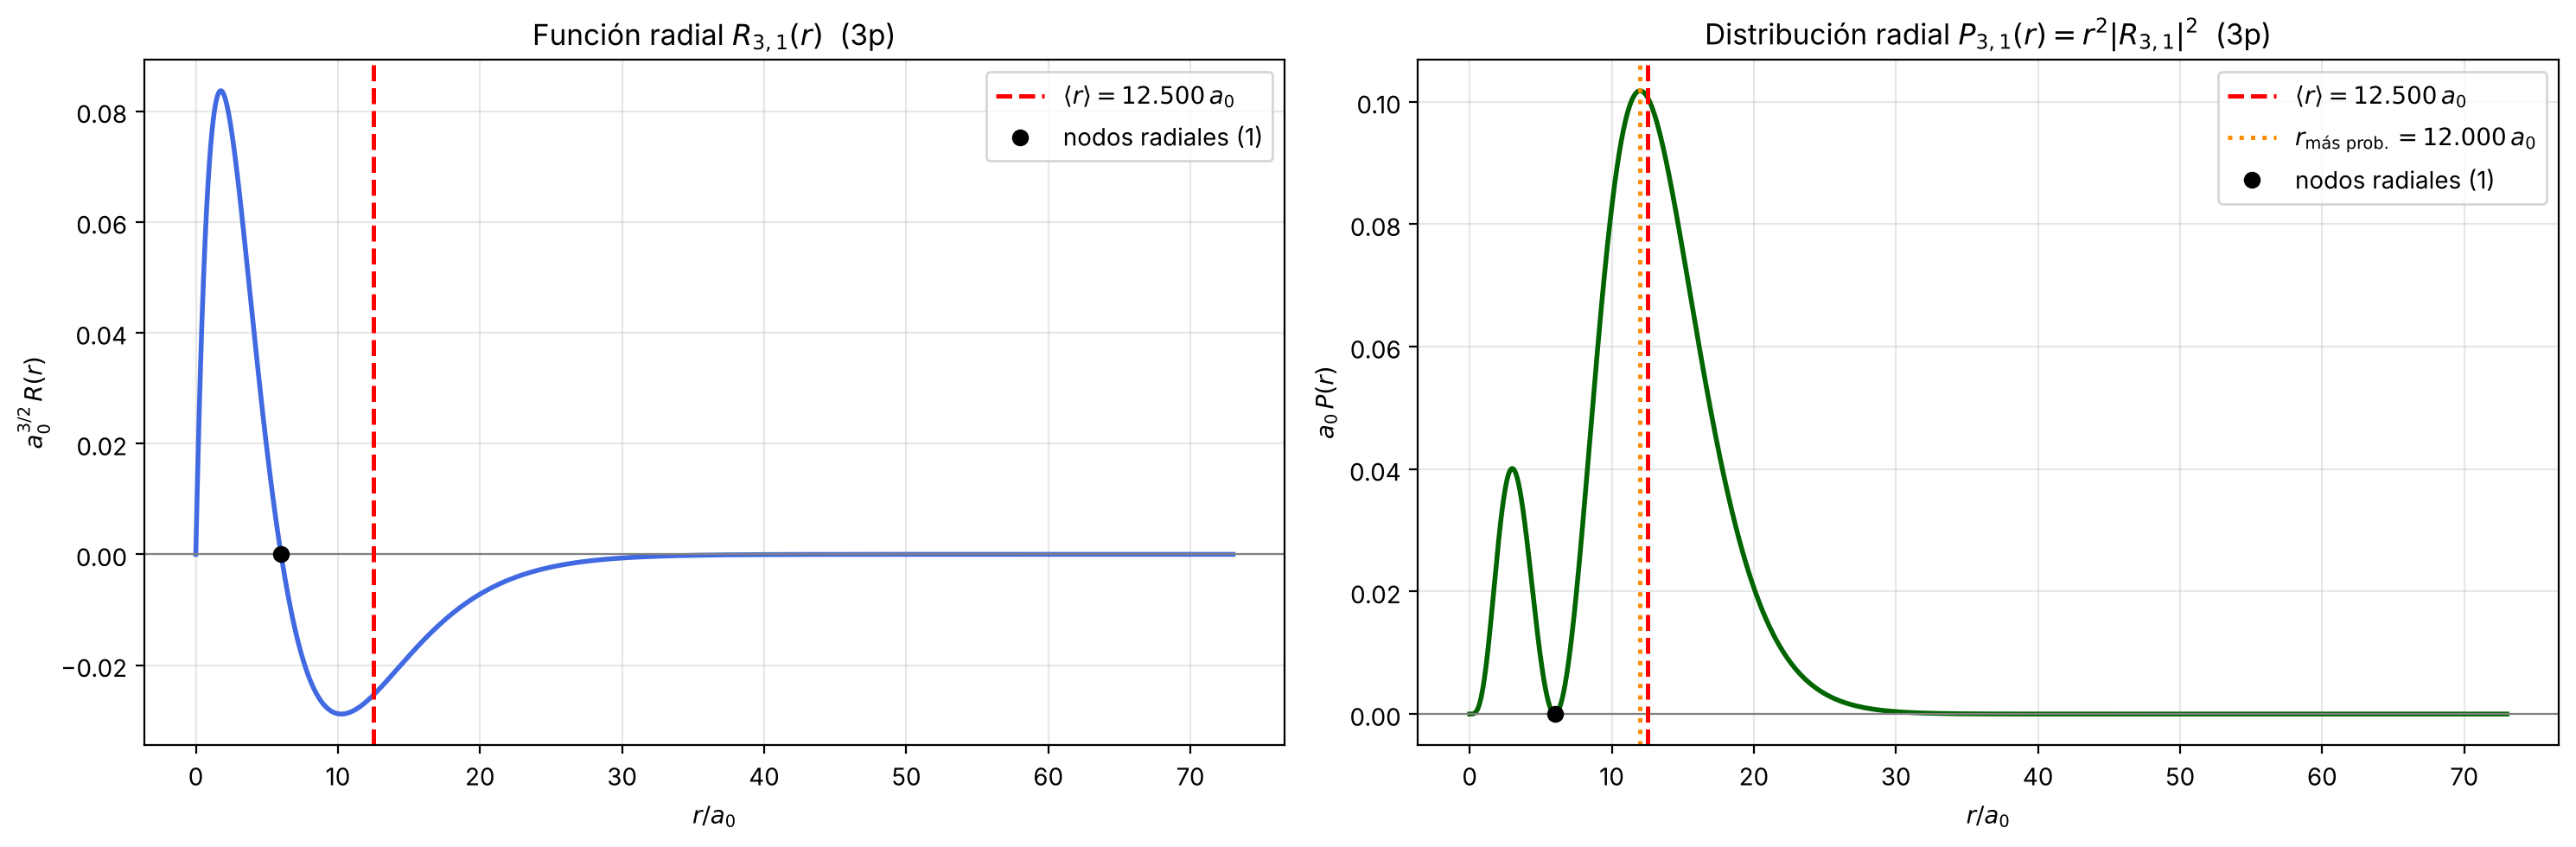

In [6]:
#@title 6) Entrada del usuario: escribe n y l { display-mode: "form" }
# =====================================================================================
#  Cambia los valores y ejecuta la celda. Si escribes la «notación» (por ejemplo 3d, 2p, 4f),
#  tiene prioridad sobre n y l.
# =====================================================================================
n = 3                      #@param {type:"integer"}
l = 1                      #@param {type:"integer"}
notacion = ""              #@param {type:"string"}
masa_reducida = False      #@param {type:"boolean"}

if notacion.strip():
    try:
        n, l = leer_notacion(notacion)
    except ValueError as error:
        diag = Diagnostico()
        diag.error(str(error))
        diag.imprimir()
        n = l = None
if n is not None:
    resultado = informe_estado(n, l, masa_reducida=masa_reducida)



╔══════════════════════════════════════════════════════════════════════════════╗
║                COMPARACIÓN DE ORBITALES · DISTRIBUCIÓN RADIAL                ║
╚══════════════════════════════════════════════════════════════════════════════╝


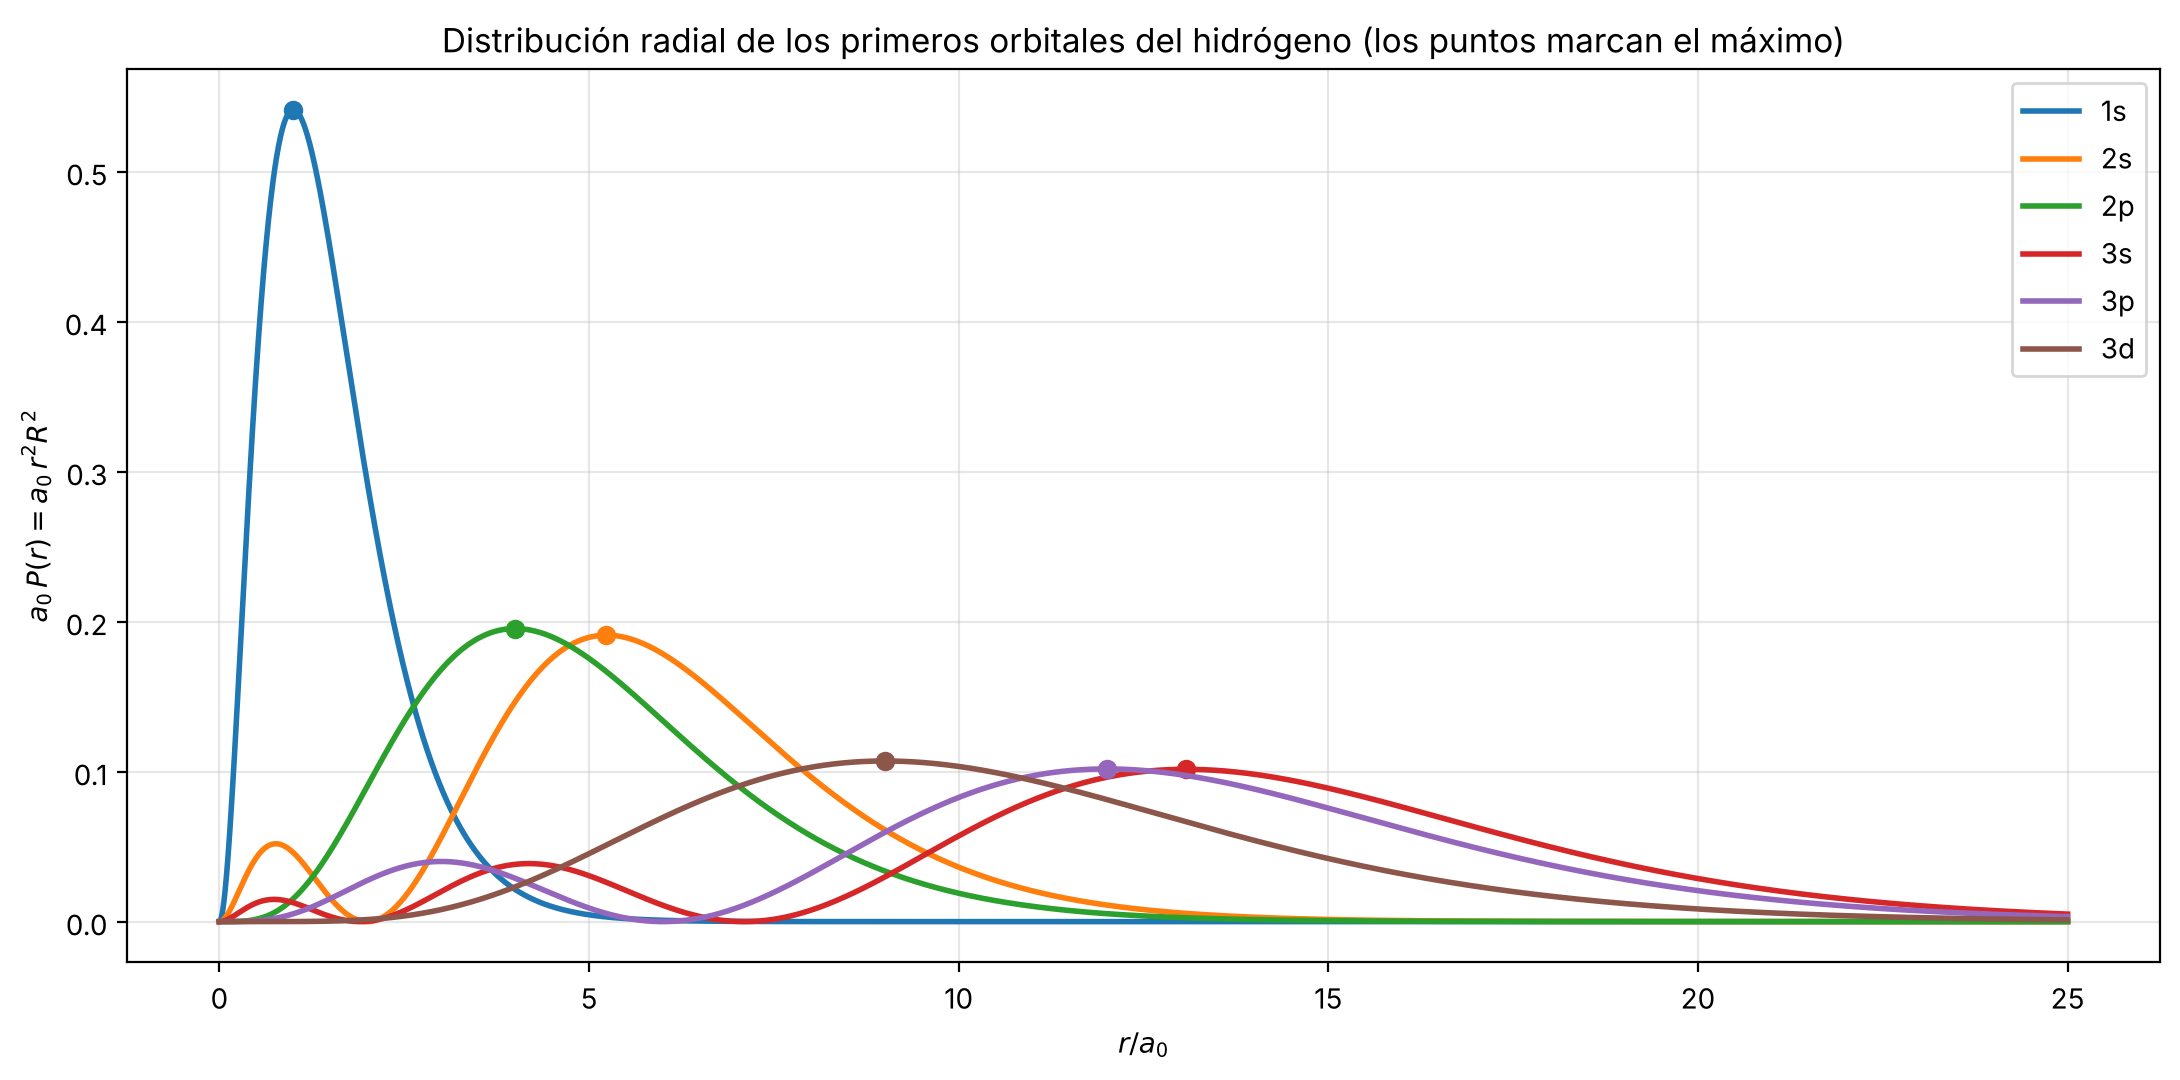


   ┌──────────┬──────────────────┬───────────────────────┬────────────┬────────────┐
   │  Estado  │  Nodos radiales  │  r más probable (a₀)  │  ⟨r⟩ (a₀)  │   E (eV)   │
   ├──────────┼──────────────────┼───────────────────────┼────────────┼────────────┤
   │    1s    │        0         │         1.0000        │   1.500    │  -13.6057  │
   │    2s    │        1         │         5.2361        │   6.000    │  -3.4014   │
   │    2p    │        0         │         4.0000        │   5.000    │  -3.4014   │
   │    3s    │        2         │        13.0740        │   13.500   │  -1.5117   │
   │    3p    │        1         │        12.0000        │   12.500   │  -1.5117   │
   │    3d    │        0         │         9.0000        │   10.500   │  -1.5117   │
   └──────────┴──────────────────┴───────────────────────┴────────────┴────────────┘

   Al crecer n el electrón se aleja del núcleo y aparecen más nodos radiales; a
   igual n, el estado con menor l penetra más cerca del núcleo (por 

In [7]:
#@title 7) Comparación de varios orbitales (r²R² frente a r/a₀) { display-mode: "form" }
# Los orbitales de la figura de la clase: 1s, 2s, 2p, 3s, 3p, 3d.
ESTADOS = [(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2)]

titulo_caja("COMPARACIÓN DE ORBITALES · DISTRIBUCIÓN RADIAL")
filas = []
fig, ax = plt.subplots(figsize=(11, 5.5))
r = np.linspace(0, 25, 5001)
for (n, l), color in zip(ESTADOS, plt.cm.tab10.colors):
    ax.plot(r, distribucion_radial(n, l, r), lw=2, color=color, label=nombre_estado(n, l))
    r_mp = radio_mas_probable(n, l)
    ax.plot(r_mp, float(distribucion_radial(n, l, r_mp)), "o", color=color)
    filas.append((nombre_estado(n, l), n - l - 1, f"{r_mp:.4f}", f"{distancia_esperada(n, l):.3f}",
                  f"{energia_estado(n)[0]:.4f}"))
ax.set_xlabel(r"$r/a_0$")
ax.set_ylabel(r"$a_0\,P(r)=a_0\,r^2R^2$")
ax.set_title("Distribución radial de los primeros orbitales del hidrógeno (los puntos marcan el máximo)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
print()
tabla(["Estado", "Nodos radiales", "r más probable (a₀)", "⟨r⟩ (a₀)", "E (eV)"], filas, sangria=3)
print()
parrafo("Al crecer n el electrón se aleja del núcleo y aparecen más nodos radiales; a igual n, el estado con menor l "
        "penetra más cerca del núcleo (por eso 3s tiene un máximo pequeño interno), aunque todos tienen la misma "
        "energía en el átomo de hidrógeno.")
